Inspecting counts, descriptive statistics, and missing values before model cleaning.

In [1]:
from pathlib import Path
import pandas as pd

# VS Code may start in the project root or in the notebook folder.
ROOT = Path.cwd()
if not (ROOT / "data" / "raw").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "data" / "raw").is_dir():
    raise FileNotFoundError("Open the project containing data/raw, and download the subset first.")
print("Project folder:", ROOT)
OUT = ROOT / "results" / "staged"
OUT.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(ROOT / "data/processed/caravan_selected.csv", parse_dates=["date"])
study = data[data["date"].between("1990-01-01", "2014-12-31")].copy()

print("Study-period shape:", study.shape)
print("Columns:", study.columns.tolist())
print("\nRows per basin:\n", study["basin"].value_counts())

Project folder: c:\Users\Pranav Yeturu\Desktop\lab2\Early-Flash-Flood-Prediction
Study-period shape: (27393, 5)
Columns: ['date', 'streamflow', 'rainfall', 'temperature', 'basin']

Rows per basin:
 basin
camels_01411300    9131
camels_05495500    9131
camels_14182500    9131
Name: count, dtype: int64


Summarize each basin
The study window is 1990–2014. Discharge is continuous, so this is regression; class counts are not applicable. Missing discharge does not mean zero flow.

In [2]:
for basin, df in study.groupby("basin"):
    # Negative discharge is invalid; zero discharge can be real.
    df = df.copy()
    invalid = (df["streamflow"] < 0).sum()
    df.loc[df["streamflow"] < 0, "streamflow"] = float("nan")
    numbers = df[["streamflow", "rainfall", "temperature"]]

    print(f"\n{basin} — invalid negative discharge values: {invalid}")
    print("Statistics:\n", numbers.describe())
    print("Missing values:\n", numbers.isna().sum())
    numbers.describe().to_csv(OUT / f"{basin}_statistics.csv")
    numbers.isna().sum().to_csv(OUT / f"{basin}_missing_values.csv", header=["missing_count"])


camels_01411300 — invalid negative discharge values: 0
Statistics:
         streamflow     rainfall  temperature
count  8877.000000  9131.000000  9131.000000
mean      1.210540     2.969377    13.306658
std       1.127911     7.031537     8.972508
min       0.140000     0.000000   -16.540000
25%       0.580000     0.000000     5.930000
50%       0.920000     0.100000    13.630000
75%       1.410000     2.135000    21.470000
max      28.230000   113.230000    32.730000
Missing values:
 streamflow     254
rainfall         0
temperature      0
dtype: int64

camels_05495500 — invalid negative discharge values: 0
Statistics:
         streamflow     rainfall  temperature
count  9100.000000  9131.000000  9131.000000
mean      0.800033     2.702981    11.852773
std       3.024819     6.200346    10.920854
min       0.000000     0.000000   -27.370000
25%       0.020000     0.000000     2.815000
50%       0.100000     0.110000    12.930000
75%       0.350000     1.990000    21.455000
max      7

In [4]:
data["date"] = pd.to_datetime(data["date"])

coverage = data.groupby("basin").agg(
    first_date=("date", "min"),
    last_date=("date", "max"),
    rows=("date", "size"),
    available_discharge=("streamflow", "count"),
)

display(coverage)

duplicates = data.duplicated(subset=["basin", "date"]).sum()
print("Duplicate basin-date rows:", duplicates)

,first_date,last_date,rows,available_discharge
basin,,,,
camels_01411300,1951-01-01,2023-12-30,26662,12530
camels_05495500,1951-01-01,2023-12-30,26662,12387
camels_14182500,1951-01-01,2023-12-30,26662,12345


Duplicate basin-date rows: 0


Inspecting the output

In [3]:
display(study.groupby("basin")[["streamflow", "rainfall", "temperature"]].mean())

,streamflow,rainfall,temperature
basin,,,
camels_01411300,1.210540,2.969377,13.306658
camels_05495500,0.800033,2.702981,11.852773
camels_14182500,5.992690,5.594210,7.976626


Compare discharge ranges across basins

In [5]:
study = data[
    data["date"].between("1990-01-01", "2014-12-31")
].copy()

# Treat negative discharge as invalid; preserve genuine zero flow.
study.loc[study["streamflow"] < 0, "streamflow"] = float("nan")

flow_summary = study.groupby("basin")["streamflow"].agg(
    observations="count",
    average="mean",
    median="median",
    minimum="min",
    maximum="max",
    standard_deviation="std",
)

display(flow_summary.round(3))

,observations,average,median,minimum,maximum,standard_deviation
basin,,,,,,
camels_01411300,8877,1.211,0.92,0.14,28.23,1.128
camels_05495500,9100,0.800,0.10,0.00,73.11,3.025
camels_14182500,9058,5.993,3.83,0.12,264.95,8.829


Inspect relationships between variables

In [6]:
for basin, df in study.groupby("basin"):
    print("\nBasin:", basin)

    display(
        df[["streamflow", "rainfall", "temperature"]]
        .corr()
        .round(3)
    )


Basin: camels_01411300


,streamflow,rainfall,temperature
streamflow,1.000,0.092,-0.266
rainfall,0.092,1.000,0.035
temperature,-0.266,0.035,1.000



Basin: camels_05495500


,streamflow,rainfall,temperature
streamflow,1.000,0.286,0.029
rainfall,0.286,1.000,0.101
temperature,0.029,0.101,1.000



Basin: camels_14182500


,streamflow,rainfall,temperature
streamflow,1.000,0.593,-0.348
rainfall,0.593,1.000,-0.292
temperature,-0.348,-0.292,1.000


Look for seasonal patterns

basin,camels_01411300,camels_05495500,camels_14182500
month,,,
1,1.441,0.443,11.140
2,1.514,0.827,8.994
3,2.048,0.942,8.751
4,1.893,1.219,8.294
5,1.341,1.842,6.274
6,1.016,1.552,3.848
7,0.695,0.674,1.003
8,0.812,0.347,0.482
9,0.676,0.410,0.695


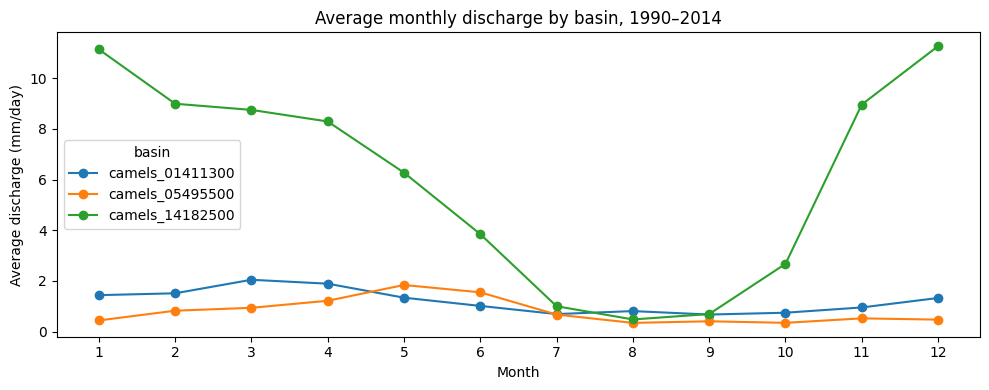

In [7]:
import matplotlib.pyplot as plt

study["month"] = study["date"].dt.month

monthly_flow = study.pivot_table(
    index="month",
    columns="basin",
    values="streamflow",
    aggfunc="mean",
)

display(monthly_flow.round(3))

ax = monthly_flow.plot(
    figsize=(10, 4),
    marker="o",
    title="Average monthly discharge by basin, 1990–2014",
)

ax.set_xlabel("Month")
ax.set_ylabel("Average discharge (mm/day)")
ax.set_xticks(range(1, 13))
plt.tight_layout()
plt.show()